<a href="https://colab.research.google.com/github/diegomartinez19/Detective-de-Senales/blob/main/SegundaSemana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1280, 32)       │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 640, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 640, 64)        │        30,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 320, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20480)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,310,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,342,340 (5.12 MB)

 Trainable params: 1,342,340 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 348ms/step - accuracy: 0.7694 - loss: 0.4409 - val_accuracy: 0.7850 - val_loss: 0.2908
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 330ms/step - accuracy: 0.9638 - loss: 0.0987 - val_accuracy: 0.9975 - val_loss: 0.0317
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 348ms/step - accuracy: 0.9950 - loss: 0.0228 - val_accuracy: 0.9800 - val_loss: 0.0430
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 319ms/step - accuracy: 0.9987 - loss: 0.0093 - val_accuracy: 0.9975 - val_loss: 0.0116
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 327ms/step - accuracy: 0.9991 - loss: 0.0061 - val_accuracy: 0.9975 - val_loss: 0.0083
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 325ms/step - accuracy: 0.9994 - loss: 0.0044 - val_accuracy: 0.9900 - val_loss: 0.0223
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 324ms/step - accuracy: 0.9997 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0070
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 325ms/step - accuracy: 0.9997 - loss: 0.0032 - val_accu

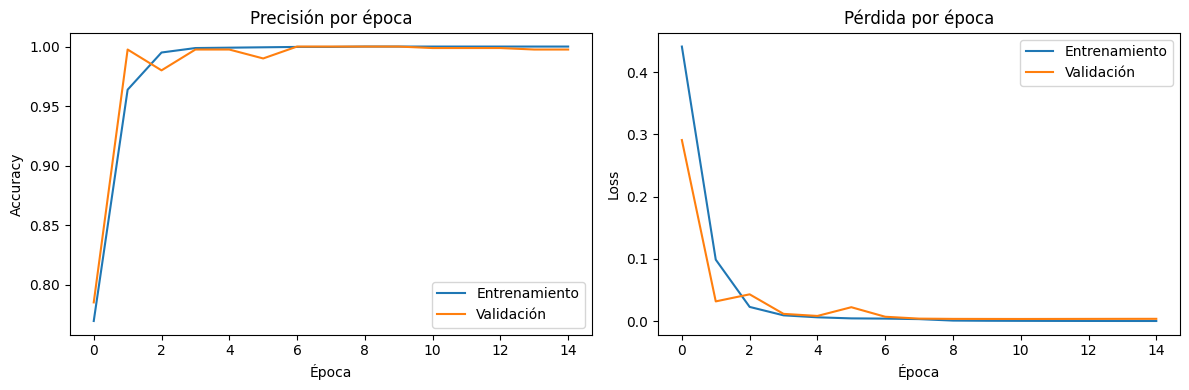

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models

# Reproducibilidad
rng = np.random.default_rng(42)
tf.random.set_seed(42)

# --- 1. Preparación de datos (misma base de la Semana 1) ---
fs = 80_000
fc = 10_000
Rs = 1_000
sps = fs // Rs
N_SIM = 16
SNR_LIST = [0, 5, 10, 15, 20]
MUESTRAS_POR_MOD = 1000
CLASES = ["ASK", "FSK", "PSK", "QAM"]
MAPA_CLASES = {nombre: idx for idx, nombre in enumerate(CLASES)}

def _t():
    return np.arange(N_SIM * sps) / fs

def gen_ask(rng):
    niveles = np.array([0.25, 0.5, 0.75, 1.0])
    a = np.repeat(rng.choice(niveles, N_SIM), sps)
    return a * np.cos(2 * np.pi * fc * _t())

def gen_fsk(rng):
    delta = 2_000
    bits = np.repeat(rng.integers(0, 2, N_SIM), sps)
    f = fc + np.where(bits == 1, delta, -delta)
    fase = 2 * np.pi * np.cumsum(f) / fs
    return np.cos(fase)

def gen_psk(rng):
    fases = rng.choice([np.pi/4, 3*np.pi/4, 5*np.pi/4, 7*np.pi/4], N_SIM)
    return np.cos(2 * np.pi * fc * _t() + np.repeat(fases, sps))

def gen_qam16(rng):
    niveles = np.array([-3, -1, 1, 3]) / np.sqrt(10)
    I = np.repeat(rng.choice(niveles, N_SIM), sps)
    Q = np.repeat(rng.choice(niveles, N_SIM), sps)
    t = _t()
    return I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)

GENERADORES = {
    "ASK": gen_ask,
    "FSK": gen_fsk,
    "PSK": gen_psk,
    "QAM": gen_qam16,
}

def agregar_awgn(senal, snr_db, rng):
    p_senal = np.mean(senal ** 2)
    p_ruido = p_senal / (10 ** (snr_db / 10))
    ruido = rng.normal(0, np.sqrt(p_ruido), senal.shape)
    return senal + ruido

X, y_str, snrs = [], [], []
for nombre, gen in GENERADORES.items():
    for i in range(MUESTRAS_POR_MOD):
        snr = SNR_LIST[i % len(SNR_LIST)]
        s = agregar_awgn(gen(rng), snr, rng)
        s = s / np.max(np.abs(s))
        X.append(s.astype(np.float32))
        y_str.append(nombre)
        snrs.append(snr)

X = np.array(X)
y = np.array([MAPA_CLASES[n] for n in y_str], dtype=np.int32)
snrs = np.array(snrs)

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snrs, test_size=0.20, stratify=y, random_state=42
)

# Conv1D espera entrada (muestras_por_senal, canales) -> (1280, 1)
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

# --- 2.2 Diseñar el modelo 1D-CNN ---
modelo = models.Sequential([
    layers.Input(shape=(X_train.shape[1], 1)),
    layers.Conv1D(filters=32, kernel_size=15, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=64, kernel_size=15, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(4, activation="softmax")
])

# --- 2.3 Compilar el modelo ---
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

# --- 2.4 Entrenar el modelo ---
historia = modelo.fit(
    X_train_cnn, y_train,
    validation_data=(X_test_cnn, y_test),
    epochs=15,
    batch_size=64,
    verbose=1
)

# --- 2.5 Guardar el modelo ---
modelo.save("modelo_modulaciones_cnn.keras")
print("Modelo guardado como 'modelo_modulaciones_cnn.keras'")

# Gráfica rápida de precisión y pérdida por época
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(historia.history["accuracy"], label="Entrenamiento")
ax1.plot(historia.history["val_accuracy"], label="Validación")
ax1.set_title("Precisión por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(historia.history["loss"], label="Entrenamiento")
ax2.plot(historia.history["val_loss"], label="Validación")
ax2.set_title("Pérdida por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()
plt.show()

2.1 Arquitecturas CNN para señales: Las redes neuronales convolucionales 1D (Conv1D) aplican filtros deslizantes sobre la serie temporal o forma de onda para detectar patrones locales repetitivos (como cambios de fase en PSK, variaciones de frecuencia en FSK, saltos de amplitud en ASK o combinaciones I/Q en 16-QAM), reduciendo parámetros frente a capas densas directas y manteniendo invarianza a desplazamientos en el tiempo.